In [5]:
import pandas as pd

df = pd.read_csv("pharmacy_sales.csv")

df.head()

,Transaction_ID,Medicine_ID,Medicine_Name,Category,Supplier_ID,Supplier_Name,Purchase_Price,Selling_Price,Quantity_Sold,Stock_Quantity,Purchase_Quantity,Expiry_Date,Sale_Date,Revenue,Profit
0,TXN00001,MED014,Pantoprazole 40mg,Gastrointestinal,SUP002,Alkem,141.50,180,8,30,120,2027-03-07,2026-02-22,1440,308.00
1,TXN00002,MED020,Mupirocin Ointment,Dermatology,SUP008,Glenmark,6.21,8,5,20,20,2027-11-07,2025-02-04,40,8.95
2,TXN00003,MED005,Azithromycin 500mg,Antibiotic,SUP003,Cipla,94.81,120,10,20,50,2026-12-22,2025-03-12,1200,251.90
3,TXN00004,MED001,Paracetamol 500mg,Analgesic,SUP003,Cipla,5.93,8,3,20,40,2027-05-06,2025-12-22,24,6.21
4,TXN00005,MED025,Multivitamin Tablets,Nutrition & Wellness,SUP010,Mankind Pharma,33.60,45,10,2,40,2027-03-07,2026-07-10,450,114.00


In [6]:
# Explore Dataset struture 
# First five records
print(df.head())

# Last five records
print(df.tail())

# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
print(df.describe())

# Data types
print(df.dtypes)

# Unique values
print(df.nunique())

  Transaction_ID Medicine_ID         Medicine_Name              Category  \
0       TXN00001      MED014     Pantoprazole 40mg      Gastrointestinal   
1       TXN00002      MED020    Mupirocin Ointment           Dermatology   
2       TXN00003      MED005    Azithromycin 500mg            Antibiotic   
3       TXN00004      MED001     Paracetamol 500mg             Analgesic   
4       TXN00005      MED025  Multivitamin Tablets  Nutrition & Wellness   

  Supplier_ID   Supplier_Name  Purchase_Price  Selling_Price  Quantity_Sold  \
0      SUP002           Alkem          141.50            180              8   
1      SUP008        Glenmark            6.21              8              5   
2      SUP003           Cipla           94.81            120             10   
3      SUP003           Cipla            5.93              8              3   
4      SUP010  Mankind Pharma           33.60             45             10   

   Stock_Quantity  Purchase_Quantity Expiry_Date   Sale_Date  Revenu

In [7]:
# Check missing values
print(df.isnull().sum())

# Missing value percentage
print(df.isnull().mean() * 100)

# Fill numerical columns with median
for col in df.select_dtypes(include="number").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill categorical columns with mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values again
print(df.isnull().sum())

Transaction_ID       0
Medicine_ID          0
Medicine_Name        0
Category             0
Supplier_ID          0
Supplier_Name        0
Purchase_Price       0
Selling_Price        0
Quantity_Sold        0
Stock_Quantity       0
Purchase_Quantity    0
Expiry_Date          0
Sale_Date            0
Revenue              0
Profit               0
dtype: int64
Transaction_ID       0.0
Medicine_ID          0.0
Medicine_Name        0.0
Category             0.0
Supplier_ID          0.0
Supplier_Name        0.0
Purchase_Price       0.0
Selling_Price        0.0
Quantity_Sold        0.0
Stock_Quantity       0.0
Purchase_Quantity    0.0
Expiry_Date          0.0
Sale_Date            0.0
Revenue              0.0
Profit               0.0
dtype: float64
Transaction_ID       0
Medicine_ID          0
Medicine_Name        0
Category             0
Supplier_ID          0
Supplier_Name        0
Purchase_Price       0
Selling_Price        0
Quantity_Sold        0
Stock_Quantity       0
Purchase_Quantity    0

In [8]:
# Count duplicate records
print("Duplicate records:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Check again
print("Remaining duplicates:", df.duplicated().sum())

# Updated dataset shape
print(df.shape)

Duplicate records: 0
Remaining duplicates: 0
(1500, 15)


In [12]:
# 1. Calculate total revenue
print("Total Revenue:", df["Revenue"].sum())

# 2. Find top 10 medicines by revenue
top_medicines = df.groupby("Medicine_Name")["Revenue"].sum()

print("\nTop 10 Medicines by Revenue:")
print(top_medicines.sort_values(ascending=False).head(10))

# 3. Find top 10 medicines by quantity sold
top_quantity = df.groupby("Medicine_Name")["Quantity_Sold"].sum()

print("\nTop 10 Medicines by Quantity Sold:")
print(top_quantity.sort_values(ascending=False).head(10))

# 4. Calculate average revenue
print("\nAverage Revenue:", df["Revenue"].mean())

# 5. Analyze monthly revenue
df["Sale_Date"] = pd.to_datetime(df["Sale_Date"])

df["Month"] = df["Sale_Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Revenue"].sum()

print("\nMonthly Revenue:")
print(monthly_revenue)

Total Revenue: 518755

Top 10 Medicines by Revenue:
Medicine_Name
Clotrimazole Cream    50180
Pantoprazole 40mg     41760
Omeprazole 20mg       40500
Losartan 50mg         39240
Levocetirizine 5mg    29520
Glimepiride 2mg       27600
Dolo 650mg            24120
Cetirizine 10mg       22560
Insulin Glargine      22560
Azithromycin 500mg    20760
Name: Revenue, dtype: int64

Top 10 Medicines by Quantity Sold:
Medicine_Name
Vitamin C 500mg      246
Metformin 500mg      243
Cefixime 200mg       235
Telmisartan 40mg     235
Fluconazole 150mg    234
Calcium + D3         232
Pantoprazole 40mg    232
Amoxicillin 500mg    231
Glimepiride 2mg      230
Omeprazole 20mg      225
Name: Quantity_Sold, dtype: int64

Average Revenue: 345.83666666666664

Monthly Revenue:
Month
2025-01    20066
2025-02    18463
2025-03    28118
2025-04    28726
2025-05    15511
2025-06    23466
2025-07    32067
2025-08    20937
2025-09    16499
2025-10    27323
2025-11    19589
2025-12    25956
2026-01    19796
2026-02   

In [13]:
# 1. Find medicines with zero stock
out_of_stock = df[df["Stock_Quantity"] == 0]

print("Out of Stock Medicines:")
print(out_of_stock[["Medicine_Name", "Stock_Quantity"]])

# 2. Find medicines with low stock (less than 10)
low_stock = df[df["Stock_Quantity"] < 10]

print("\nLow Stock Medicines:")
print(low_stock[["Medicine_Name", "Stock_Quantity"]])

# 3. Calculate total available stock
print("\nTotal Available Stock:", df["Stock_Quantity"].sum())

# 4. Average stock quantity
print("Average Stock:", df["Stock_Quantity"].mean())

Out of Stock Medicines:
             Medicine_Name  Stock_Quantity
21           Losartan 50mg               0
26         Omeprazole 20mg               0
73       Pantoprazole 40mg               0
115          Losartan 50mg               0
122         Cefixime 200mg               0
152     Clotrimazole Cream               0
165     Mupirocin Ointment               0
179      Atorvastatin 10mg               0
209      Amoxicillin 500mg               0
213        Omeprazole 20mg               0
224        Vitamin C 500mg               0
246        Vitamin C 500mg               0
289       Insulin Glargine               0
295     Clotrimazole Cream               0
298   Multivitamin Tablets               0
390       Domperidone 10mg               0
478         Amlodipine 5mg               0
479     Mupirocin Ointment               0
480             Dolo 650mg               0
483        Omeprazole 20mg               0
510         Cefixime 200mg               0
553     Azithromycin 500mg    

In [14]:
# 1. Total purchase quantity by supplier
supplier_quantity = df.groupby("Supplier_Name")["Purchase_Quantity"].sum()

print("Supplier-wise Purchase Quantity:")
print(supplier_quantity.sort_values(ascending=False))

# 2. Average purchase price by supplier
supplier_price = df.groupby("Supplier_Name")["Purchase_Price"].mean()

print("\nAverage Purchase Price:")
print(supplier_price.sort_values(ascending=False))

# 3. Total purchase cost by supplier
df["Purchase_Cost"] = df["Purchase_Price"] * df["Purchase_Quantity"]

supplier_cost = df.groupby("Supplier_Name")["Purchase_Cost"].sum()

print("\nSupplier-wise Purchase Cost:")
print(supplier_cost.sort_values(ascending=False))

Supplier-wise Purchase Quantity:
Supplier_Name
Cipla             22240
Sun Pharma        11695
Sanofi            10260
Alkem              9650
Glenmark           8890
Abbott             8825
Zydus              8470
Dr Reddy's         8410
Mankind Pharma     7140
Torrent Pharma     7100
Micro Labs         5645
USV                4810
FDC                4230
GSK                4050
Himalaya           3820
Dabur              3760
Name: Purchase_Quantity, dtype: int64

Average Purchase Price:
Supplier_Name
GSK               212.020000
Zydus             117.209800
Dr Reddy's        112.171875
Alkem             106.209130
Micro Labs         96.020000
Sanofi             91.748879
Mankind Pharma     81.501667
FDC                69.350000
Dabur              67.700000
Torrent Pharma     45.212386
Himalaya           44.470000
Cipla              36.204535
Abbott             34.614457
Sun Pharma         34.195685
USV                28.340000
Glenmark           17.681389
Name: Purchase_Price, dtype:

In [15]:
# Convert expiry date into datetime format
df["Expiry_Date"] = pd.to_datetime(df["Expiry_Date"], errors="coerce")

# Get today's date
today = pd.Timestamp.today().normalize()

# 1. Find expired medicines
expired = df[df["Expiry_Date"] < today]

print("Expired Medicines:")
print(expired[["Medicine_Name", "Expiry_Date"]])

# 2. Find medicines expiring within 90 days
near_expiry = df[
    (df["Expiry_Date"] >= today) &
    (df["Expiry_Date"] <= today + pd.Timedelta(days=90))
]

print("\nMedicines Nearing Expiry:")
print(near_expiry[["Medicine_Name", "Expiry_Date"]])

# 3. Count expired medicines
print("\nTotal Expired Records:", len(expired))

# 4. Count medicines nearing expiry
print("Total Near Expiry Records:", len(near_expiry))

Expired Medicines:
           Medicine_Name Expiry_Date
19    Levocetirizine 5mg  2026-05-11
32       Vitamin C 500mg  2026-05-11
37      Domperidone 10mg  2026-10-08
57     Fluconazole 150mg  2026-10-08
67         Losartan 50mg  2026-05-11
...                  ...         ...
1488  Levocetirizine 5mg  2026-04-14
1489     Cetirizine 10mg  2026-06-04
1490     Metformin 500mg  2026-07-26
1491          Dolo 650mg  2026-09-15
1492   Amoxicillin 500mg  2026-11-05

[116 rows x 2 columns]

Medicines Nearing Expiry:
           Medicine_Name Expiry_Date
2     Azithromycin 500mg  2026-12-22
7     Salbutamol Inhaler  2026-12-22
8      Paracetamol 500mg  2026-12-22
13        Diclofenac Gel  2027-01-21
15       Glimepiride 2mg  2027-01-21
...                  ...         ...
1471  ORS Ready-to-Drink  2026-11-17
1474     Vitamin C 500mg  2027-01-21
1478          ORS Sachet  2026-11-17
1485   Fluconazole 150mg  2026-12-22
1493   Atorvastatin 10mg  2026-12-27

[477 rows x 2 columns]

Total Expired Rec

In [16]:
# 1. Category-wise revenue
category_revenue = df.groupby("Category")["Revenue"].sum()

print("Category-wise Revenue:")
print(category_revenue.sort_values(ascending=False))

# 2. Category-wise profit
category_profit = df.groupby("Category")["Profit"].sum()

print("\nCategory-wise Profit:")
print(category_profit.sort_values(ascending=False))

# 3. Category-wise quantity sold
category_quantity = df.groupby("Category")["Quantity_Sold"].sum()

print("\nCategory-wise Quantity Sold:")
print(category_quantity.sort_values(ascending=False))

# 4. Average selling price by category
category_price = df.groupby("Category")["Selling_Price"].mean()

print("\nAverage Selling Price:")
print(category_price)

Category-wise Revenue:
Category
Gastrointestinal        87895
Cardiovascular          65813
Dermatology             65700
Nutrition & Wellness    62735
Antibiotic              60370
Diabetes Care           58665
Antihistamine           52080
Analgesic               37432
Respiratory             28065
Name: Revenue, dtype: int64

Category-wise Profit:
Category
Gastrointestinal        19963.47
Cardiovascular          16837.38
Antihistamine           14729.64
Nutrition & Wellness    14601.03
Dermatology             13471.01
Diabetes Care           13462.62
Antibiotic              12022.31
Analgesic                8330.72
Respiratory              7576.51
Name: Profit, dtype: float64

Category-wise Quantity Sold:
Category
Nutrition & Wellness    995
Cardiovascular          780
Analgesic               695
Diabetes Care           661
Antibiotic              639
Gastrointestinal        618
Dermatology             612
Respiratory             509
Antihistamine           352
Name: Quantity_Sold, 

In [17]:
# 1. Best-selling medicine by revenue
best_medicine = df.groupby("Medicine_Name")["Revenue"].sum().idxmax()

print("Best Medicine by Revenue:", best_medicine)

# 2. Most profitable medicine
profitable_medicine = df.groupby("Medicine_Name")["Profit"].sum().idxmax()

print("\nMost Profitable Medicine:", profitable_medicine)

# 3. Most profitable category
best_category = df.groupby("Category")["Profit"].sum().idxmax()

print("\nMost Profitable Category:", best_category)

# 4. Best-performing supplier by purchase quantity
best_supplier = df.groupby("Supplier_Name")["Purchase_Quantity"].sum().idxmax()

print("\nBest Supplier by Purchase Quantity:", best_supplier)

# 5. Total revenue
print("\nTotal Revenue:", df["Revenue"].sum())

# 6. Total profit
print("Total Profit:", df["Profit"].sum())

# 7. Total quantity sold
print("Total Quantity Sold:", df["Quantity_Sold"].sum())

# 8. Average selling price
print("Average Selling Price:", df["Selling_Price"].mean())

Best Medicine by Revenue: Clotrimazole Cream

Most Profitable Medicine: Losartan 50mg

Most Profitable Category: Gastrointestinal

Best Supplier by Purchase Quantity: Cipla

Total Revenue: 518755
Total Profit: 120994.69
Total Quantity Sold: 5861
Average Selling Price: 88.60666666666667


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

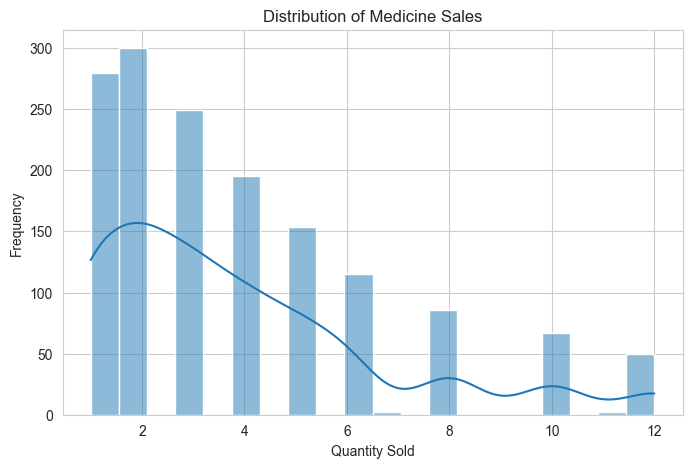

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Quantity_Sold", bins=20, kde=True)

plt.title("Distribution of Medicine Sales")
plt.xlabel("Quantity Sold")
plt.ylabel("Frequency")

plt.show()

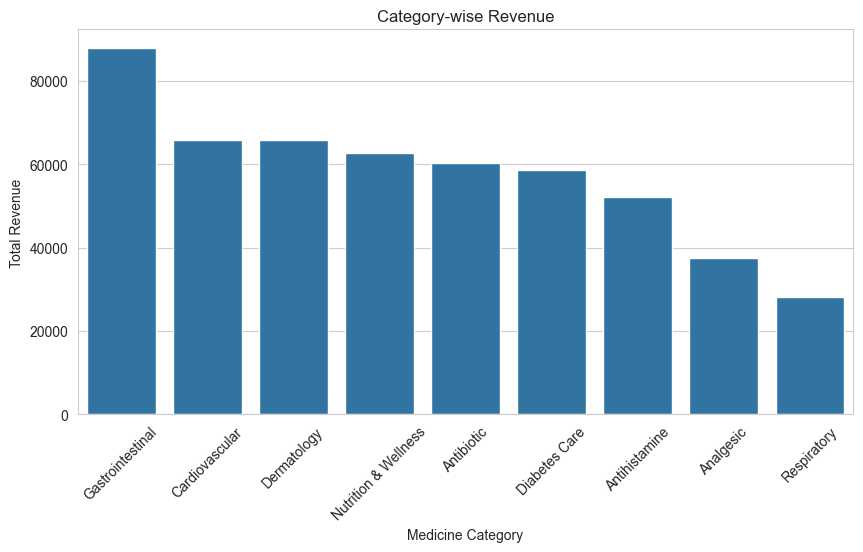

In [20]:
category_sales = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(x=category_sales.index, y=category_sales.values)

plt.title("Category-wise Revenue")
plt.xlabel("Medicine Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

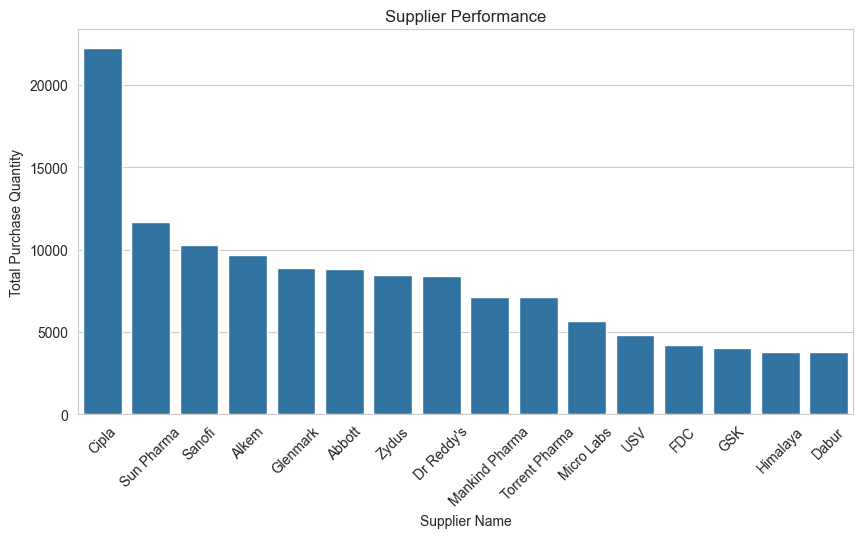

In [21]:
supplier_sales = df.groupby("Supplier_Name")["Purchase_Quantity"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(x=supplier_sales.index, y=supplier_sales.values)

plt.title("Supplier Performance")
plt.xlabel("Supplier Name")
plt.ylabel("Total Purchase Quantity")
plt.xticks(rotation=45)

plt.show()

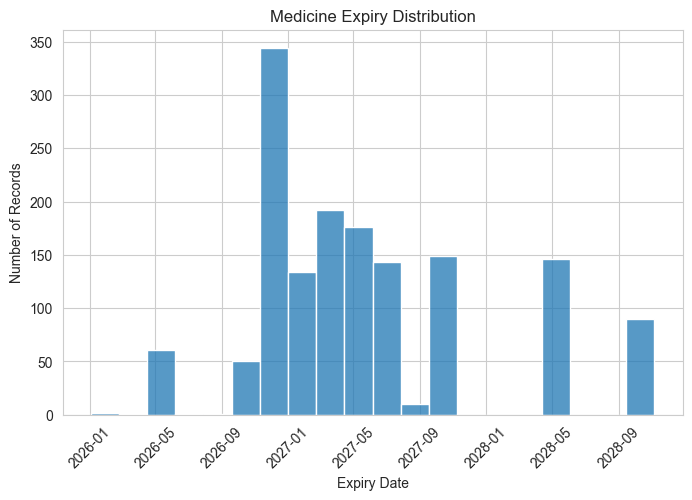

In [22]:
df["Expiry_Date"] = pd.to_datetime(df["Expiry_Date"], errors="coerce")

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Expiry_Date", bins=20)

plt.title("Medicine Expiry Distribution")
plt.xlabel("Expiry Date")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

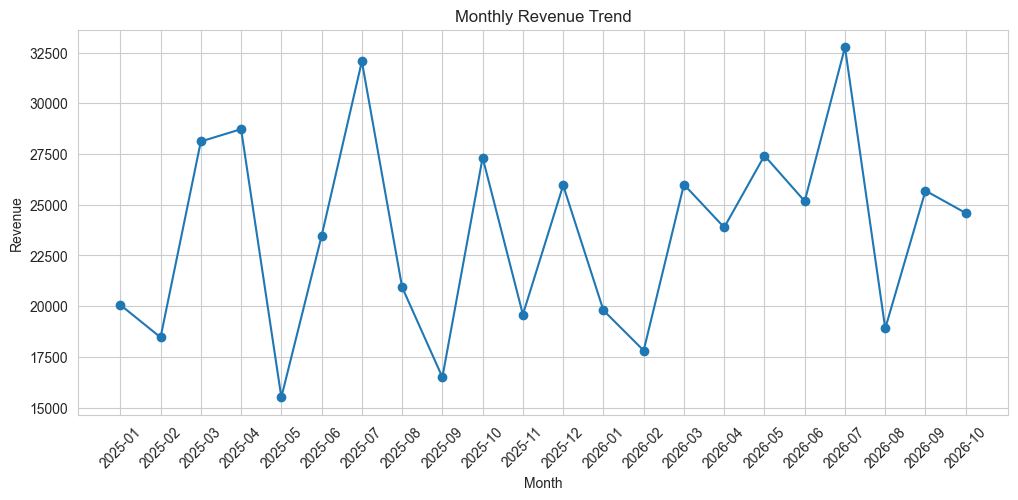

In [23]:
df["Sale_Date"] = pd.to_datetime(df["Sale_Date"], errors="coerce")

monthly_revenue = df.groupby(df["Sale_Date"].dt.to_period("M"))["Revenue"].sum()

plt.figure(figsize=(12, 5))

plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

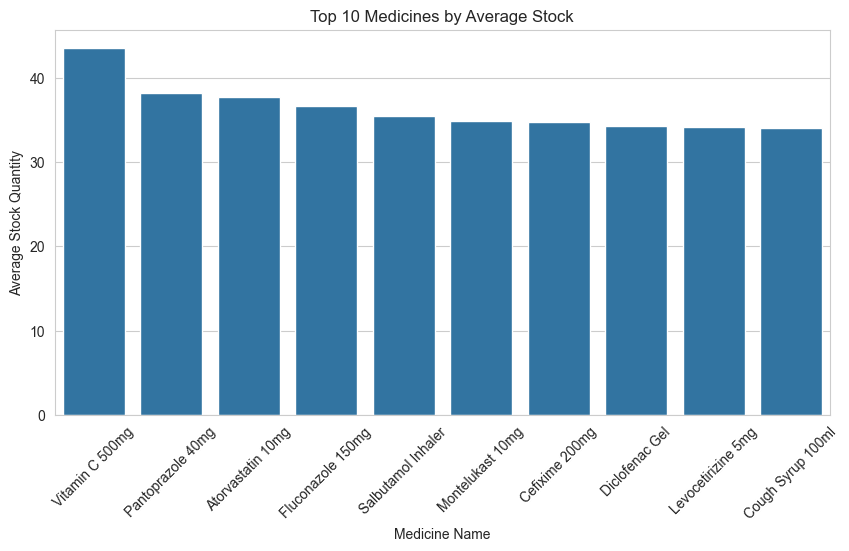

In [24]:
inventory = df.groupby("Medicine_Name")["Stock_Quantity"].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=inventory.index, y=inventory.values)

plt.title("Top 10 Medicines by Average Stock")
plt.xlabel("Medicine Name")
plt.ylabel("Average Stock Quantity")
plt.xticks(rotation=45)

plt.show()

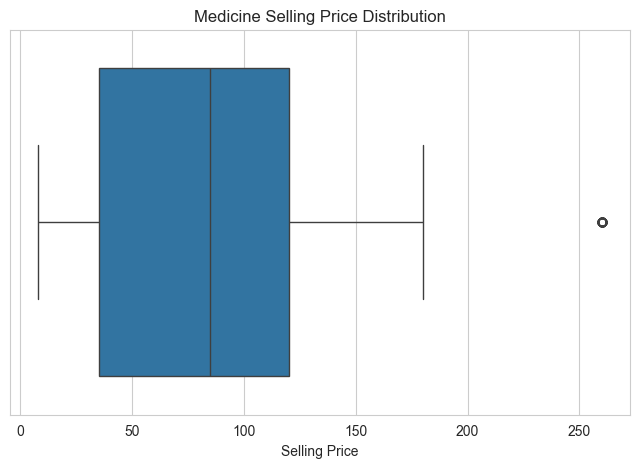

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Selling_Price"])

plt.title("Medicine Selling Price Distribution")
plt.xlabel("Selling Price")

plt.show()

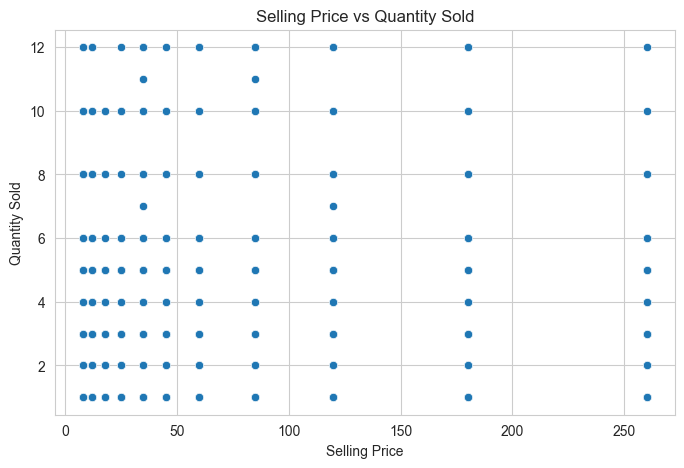

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Selling_Price", y="Quantity_Sold")

plt.title("Selling Price vs Quantity Sold")
plt.xlabel("Selling Price")
plt.ylabel("Quantity Sold")

plt.show()

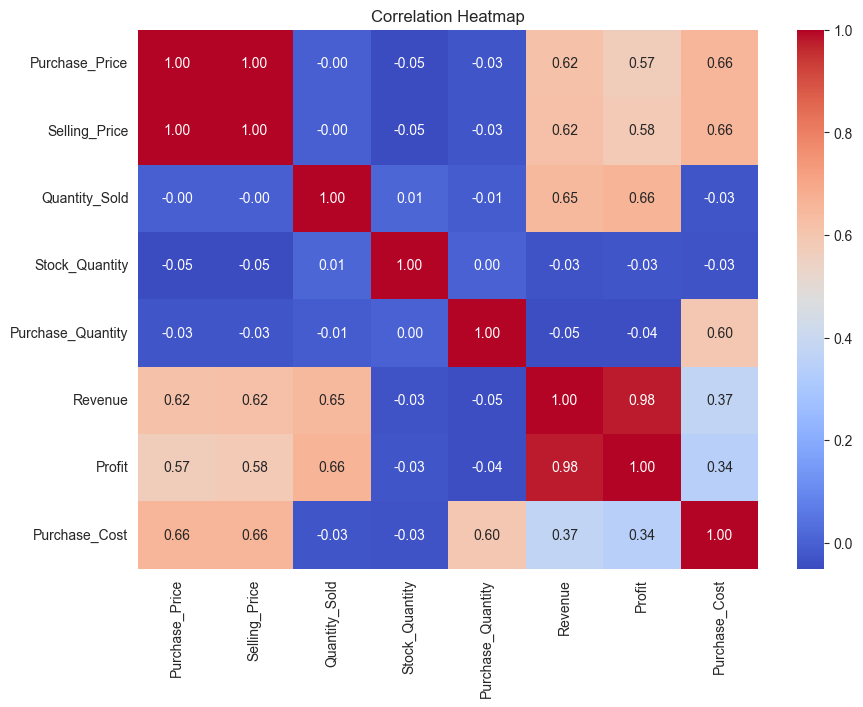

In [28]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

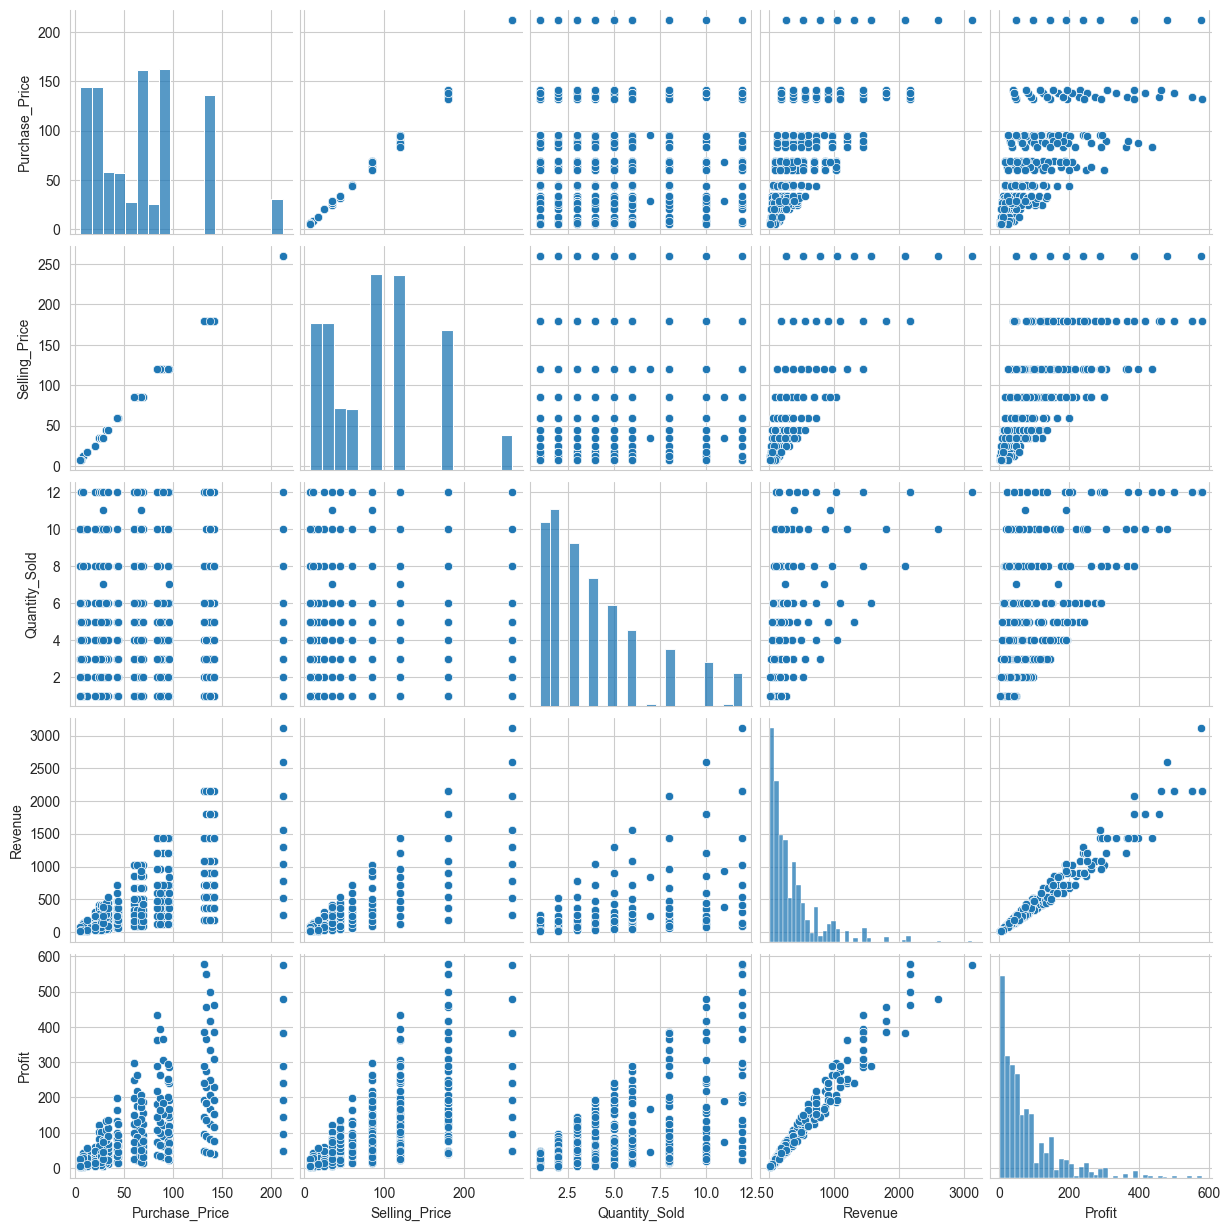

In [30]:
selected_columns = [
    "Purchase_Price",
    "Selling_Price",
    "Quantity_Sold",
    "Revenue",
    "Profit"
]

sns.pairplot(df[selected_columns])

plt.show()

In [31]:
import pandas as pd

In [32]:
total_revenue = df["Revenue"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity_Sold"].sum()
total_transactions = df["Transaction_ID"].nunique()
total_medicines = df["Medicine_ID"].nunique()

summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Profit",
        "Total Quantity Sold",
        "Total Transactions",
        "Unique Medicines"
    ],
    "Value": [
        total_revenue,
        total_profit,
        total_quantity,
        total_transactions,
        total_medicines
    ]
})

display(summary)

,Metric,Value
0,Total Revenue,518755.00
1,Total Profit,120994.69
2,Total Quantity Sold,5861.00
3,Total Transactions,1500.00
4,Unique Medicines,30.00


In [33]:
category_report = df.groupby("Category").agg({
    "Revenue": "sum",
    "Profit": "sum",
    "Quantity_Sold": "sum"
}).reset_index()

category_report = category_report.sort_values(
    by="Revenue", ascending=False
)

display(category_report)

,Category,Revenue,Profit,Quantity_Sold
6,Gastrointestinal,87895,19963.47,618
3,Cardiovascular,65813,16837.38,780
4,Dermatology,65700,13471.01,612
7,Nutrition & Wellness,62735,14601.03,995
1,Antibiotic,60370,12022.31,639
5,Diabetes Care,58665,13462.62,661
2,Antihistamine,52080,14729.64,352
0,Analgesic,37432,8330.72,695
8,Respiratory,28065,7576.51,509


In [34]:
df["Purchase_Cost"] = (
    df["Purchase_Price"] * df["Purchase_Quantity"]
)

supplier_report = df.groupby("Supplier_Name").agg({
    "Purchase_Quantity": "sum",
    "Purchase_Cost": "sum",
    "Purchase_Price": "mean"
}).reset_index()

supplier_report = supplier_report.sort_values(
    by="Purchase_Quantity", ascending=False
)

display(supplier_report)

,Supplier_Name,Purchase_Quantity,Purchase_Cost,Purchase_Price
2,Cipla,22240,810049.10,36.204535
12,Sun Pharma,11695,416896.50,34.195685
11,Sanofi,10260,939430.20,91.748879
1,Alkem,9650,1031206.30,106.209130
7,Glenmark,8890,149242.20,17.681389
0,Abbott,8825,304093.50,34.614457
15,Zydus,8470,979715.20,117.209800
4,Dr Reddy's,8410,886874.15,112.171875
9,Mankind Pharma,7140,580449.80,81.501667
13,Torrent Pharma,7100,299837.00,45.212386


In [36]:
with pd.ExcelWriter("Pharmacy_Final_Report.xlsx") as writer:

    summary.to_excel(
        writer, sheet_name="Overall Summary", index=False
    )

    category_report.to_excel(
        writer, sheet_name="Category Sales", index=False
    )

    supplier_report.to_excel(
        writer, sheet_name="Supplier Performance", index=False
    )

    inventory_report.to_excel(
        writer, sheet_name="Inventory and Expiry", index=False
    )

print("Pharmacy Final Report Generated Successfully!")

Pharmacy Final Report Generated Successfully!
